<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Fingerprint groups are not identities

**Which handshake differences change a group, and which disappear during
fingerprinting?** We will parse authored TLS bytes with VGI TLSFP, compare JA3 with
base JA4 TLS-client grouping, and retain incomplete, wrong-role and missing input.
VGI X.509 will parse two synthetic certificates so we can correlate separate
fingerprint domains through explicit capture IDs.

These are synthetic byte records and authored associations, not live captures or
completed TLS sessions. No network inspection occurs. A fingerprint groups selected
handshake properties; it does not identify a person, a unique client, a trusted server,
or malicious traffic. Certificate fingerprints identify different bytes and cannot
be joined directly to TLS client fingerprints.

## Choose the grouping rule

`USE_JA4=True` groups successfully parsed ClientHellos by the worker's base JA4
TLS-client fingerprint. The experiment switches to `False`, using JA3. Every input
record remains in the audit, and both raw fingerprints are computed regardless of
this setting. Restart the kernel and run all after changing the boolean.

In [1]:
USE_JA4 = True

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from notebook_support import finish, prose, theme

if type(USE_JA4) is not bool:
    raise ValueError("USE_JA4 must be True or False.")
coverage = groups = checks = pd.DataFrame()
scheme = "Base JA4" if USE_JA4 else "JA3"
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-tlsfp/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-tlsfp/notebooks/pyproject.toml.

## Attach TLSFP and its certificate companion

Both literal `github-auto` locations fetch, verify and cache their v0.4.0 native
releases. Neither connection requires a local Rust/Go build. TLSFP parses handshake
bytes; X.509 parses certificate PEM bytes. The notebook invokes only local parsing
functions and does not call endpoint-inspection functions.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tlsfp' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-tlsfp@v0.4.0');
ATTACH 'x509' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-x509@v0.4.0');

,Success


## Expand authored variants into capture records

The five ClientHello variants change framing, cipher order, GREASE code points or
the supplied server name. Their repetitions create eight parseable client records.
Additional inputs include a plausible header with an incomplete body, a ServerHello,
non-handshake text and SQL NULL. The certificate associations are explicitly authored
here; they are not inferred from a hash or checked against a completed handshake.

The builder follows the worker's canonical test-fixture field shape. It is a small
encoding fixture, not a packet capture or TLS implementation. Some extension bodies
are intentionally minimal; successful field parsing does not establish negotiability.

In [4]:
%%sql
CREATE TABLE byte_files AS
SELECT regexp_extract(filename,'([^/]+)\.bin$',1) AS pattern_id,content AS bytes
FROM read_blob('fixtures/*.bin');
CREATE TABLE patterns AS SELECT * FROM (VALUES
 ('base',2,'shared-soon'),('record',1,'shared-soon'),('reversed-ciphers',2,'shared-soon'),
 ('different-grease',1,'shared-soon'),('other-server',2,'long'),
 ('header-only',1,NULL),('server-hello',1,NULL),('not-handshake',1,NULL),('missing',1,NULL)
) t(pattern_id,repetitions,certificate_id);
CREATE TABLE captures AS
SELECT row_number() OVER(ORDER BY p.pattern_id,copy_no) AS capture_id,p.pattern_id,
 p.certificate_id,b.bytes
FROM patterns p LEFT JOIN byte_files b USING(pattern_id)
CROSS JOIN LATERAL range(1,p.repetitions+1) t(copy_no);
SELECT pattern_id,count(*) AS capture_records,count(bytes) AS supplied_bytes,
 first(certificate_id) AS authored_certificate_id
FROM captures GROUP BY pattern_id ORDER BY pattern_id;

,pattern_id,capture_records,supplied_bytes,authored_certificate_id
0,base,2,2,shared-soon
1,different-grease,1,1,shared-soon
2,header-only,1,1,None
3,missing,1,0,None
4,not-handshake,1,1,None
5,other-server,2,2,long
6,record,1,1,shared-soon
7,reversed-ciphers,2,2,shared-soon
8,server-hello,1,1,None


## Separate a plausible header from a parsed ClientHello

`is_tls_handshake` is a cheap structural guard for ClientHello **or** ServerHello
headers. A true result does not guarantee a complete ClientHello. The header-only
fixture passes that guard but fails client parsing; the ServerHello also passes the
guard and has a JA3S result while its client fingerprints remain NULL.

Materialize all outputs before grouping. Missing bytes, an unrecognized header and
a recognized header without a client parse remain separate. The decoder preserves
wire-order lists and GREASE values; fingerprint normalization is a later operation.

In [5]:
%%sql
CREATE TABLE decoded AS
SELECT *,tlsfp.main.is_tls_handshake(bytes) AS header_recognized,
 tlsfp.main.parse_client_hello(bytes) AS parsed,
 tlsfp.main.ja3(bytes) AS ja3,tlsfp.main.ja3_string(bytes) AS ja3_string,
 tlsfp.main.ja4(bytes) AS ja4,tlsfp.main.ja4_raw(bytes) AS ja4_raw,
 tlsfp.main.ja3s(bytes) AS ja3s
FROM captures;
CREATE TABLE capture_audit AS
SELECT *,CASE WHEN bytes IS NULL THEN 'Missing input'
 WHEN parsed IS NOT NULL THEN 'ClientHello decoded'
 WHEN header_recognized THEN 'Header recognized; no ClientHello'
 ELSE 'Header not recognized' END AS input_state
FROM decoded;
SELECT pattern_id,first(header_recognized) AS header_recognized,
 first(parsed.sni) AS server_name,first(parsed.version) AS legacy_version,
 first(ja3) AS ja3,first(ja4) AS base_ja4,first(ja3s) AS server_ja3s
FROM capture_audit GROUP BY pattern_id ORDER BY pattern_id;

,pattern_id,header_recognized,server_name,legacy_version,ja3,base_ja4,server_ja3s
0,base,True,shared-soon.example,771,d073ecbd407a031c76ecda2e9c168b98,t13d1516h2_8daaf6152771_e5627efa2ab1,None
1,different-grease,True,shared-soon.example,771,d073ecbd407a031c76ecda2e9c168b98,t13d1516h2_8daaf6152771_e5627efa2ab1,None
2,header-only,True,None,<NA>,None,None,None
3,missing,<NA>,None,<NA>,None,None,None
4,not-handshake,False,None,<NA>,None,None,None
5,other-server,True,long.example,771,d073ecbd407a031c76ecda2e9c168b98,t13d1516h2_8daaf6152771_e5627efa2ab1,None
6,record,True,shared-soon.example,771,d073ecbd407a031c76ecda2e9c168b98,t13d1516h2_8daaf6152771_e5627efa2ab1,None
7,reversed-ciphers,True,shared-soon.example,771,df61960f83082fa6b8c90f587ce8bbce,t13d1516h2_8daaf6152771_e5627efa2ab1,None
8,server-hello,True,None,<NA>,None,None,7bee5c1d424b7e5f943b06983bb11422


In [6]:
%%sql coverage <<
SELECT input_state,count(*) AS capture_records FROM capture_audit
GROUP BY input_state ORDER BY capture_records DESC,input_state;

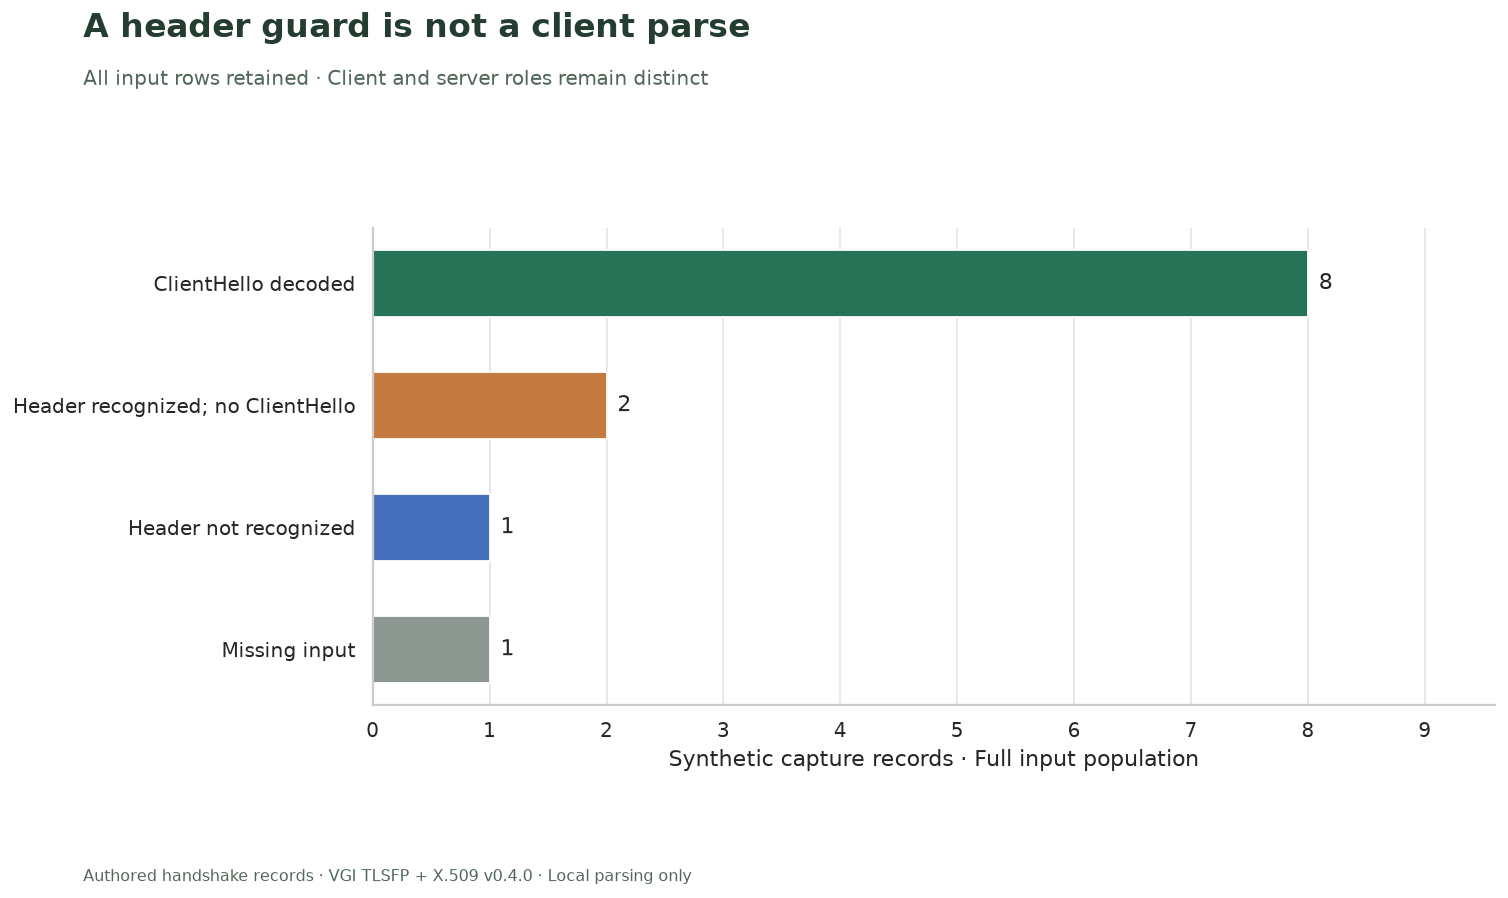

The audit retains **12 input records**. A plausible header and a ServerHello can both pass the guard without yielding a ClientHello. This population audit stays fixed when the grouping rule changes.

In [7]:
palette = {
    "ClientHello decoded": "#267358",
    "Header recognized; no ClientHello": "#c57b40",
    "Header not recognized": "#456fba",
    "Missing input": "#8b9790",
}
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    coverage.input_state,
    coverage.capture_records,
    color=[palette[s] for s in coverage.input_state],
    height=0.55,
)
ax.bar_label(bars, padding=6, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, int(coverage.capture_records.max()) * 1.2)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Synthetic capture records · Full input population")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "A header guard is not a client parse",
    "All input rows retained · Client and server roles remain distinct",
    "01_input_coverage.png",
    bottom=0.12,
)
prose(
    f"The audit retains **{int(coverage.capture_records.sum())} input records**. "
    "A plausible header and a ServerHello can both pass the guard without yielding a ClientHello. "
    "This population audit stays fixed when the grouping rule changes."
)

## Inspect what the fingerprint normalization keeps

JA3 uses the legacy version and preserves cipher/extension wire order after stripping
GREASE. Base JA4 uses the effective supported TLS version and sorts cipher/extension
lists, while retaining signature-algorithm order in its calculation. The fixture
reverses only the cipher list. It does not demonstrate invariance to arbitrary changes.

The baseline's legacy version is 771 (TLS 1.2's code), while its supported-versions
extension makes the base JA4 prefix `t13` for TLS 1.3. This is advertised capability,
not an observed negotiated protocol. Different SNI text can share the same fingerprint;
the base JA4 prefix records the presence/type of SNI, not the entire server name.

In [8]:
%%sql
SELECT pattern_id,first(parsed.ciphers) AS decoded_ciphers,
 first(parsed.extensions) AS decoded_extensions,first(ja3_string) AS ja3_pre_hash,
 first(ja4_raw) AS base_ja4_raw
FROM decoded WHERE pattern_id IN ('base','reversed-ciphers','different-grease')
GROUP BY pattern_id ORDER BY pattern_id;

,pattern_id,decoded_ciphers,decoded_extensions,ja3_pre_hash,base_ja4_raw
0,base,"[2570, 47, 53, 156, 157, 4865, 4866, 4867, 491...","[0, 5, 10, 11, 13, 16, 18, 21, 23, 27, 2570, 3...","771,47-53-156-157-4865-4866-4867-49171-49172-4...","t13d1516h2_002f,0035,009c,009d,1301,1302,1303,..."
1,different-grease,"[10794, 47, 53, 156, 157, 4865, 4866, 4867, 49...","[0, 5, 10, 11, 13, 16, 18, 21, 23, 27, 10794, ...","771,47-53-156-157-4865-4866-4867-49171-49172-4...","t13d1516h2_002f,0035,009c,009d,1301,1302,1303,..."
2,reversed-ciphers,"[2570, 52393, 52392, 49200, 49199, 49196, 4919...","[0, 5, 10, 11, 13, 16, 18, 21, 23, 27, 2570, 3...","771,52393-52392-49200-49199-49196-49195-49172-...","t13d1516h2_002f,0035,009c,009d,1301,1302,1303,..."


## Parse certificate bytes and correlate through capture IDs

The two synthetic self-signed certificate files come from the X.509 notebook fixtures.
Their SHA-256 fingerprints identify complete certificate DER bytes. The TLS client
fingerprints describe a different object and use different fields and algorithms.

Build an explicit capture-to-certificate table, then join on `capture_id`. This is
the kind of correlation key a real capture system must supply. It is not a proof of
certificate trust, hostname validity or a successful TLS session. Both certificate
and handshake parsing remain local.

In [9]:
%%sql
CREATE TABLE certificate_inventory AS
SELECT regexp_extract(filename,'([^/]+)\.pem$',1) AS certificate_id,
 x509.main.cert_fingerprint(content) AS certificate_sha256,
 x509.main.cert_subject(content) AS certificate_subject
FROM read_text('fixtures/*.pem');
CREATE TABLE capture_certificates AS
SELECT c.capture_id,i.certificate_sha256,i.certificate_subject
FROM captures c JOIN certificate_inventory i USING(certificate_id);
CREATE TABLE client_records AS
SELECT d.*,c.certificate_sha256,
 CASE WHEN {{ USE_JA4 }} THEN d.ja4 ELSE d.ja3 END AS selected_fingerprint
FROM decoded d LEFT JOIN capture_certificates c USING(capture_id)
WHERE d.parsed IS NOT NULL;
SELECT capture_id,pattern_id,parsed.sni AS server_name,selected_fingerprint,
 certificate_sha256 FROM client_records ORDER BY capture_id;

,capture_id,pattern_id,server_name,selected_fingerprint,certificate_sha256
0,1,base,shared-soon.example,t13d1516h2_8daaf6152771_e5627efa2ab1,f04bc8196741c4b94a0a1e08395724f4659eebb5ffc266...
1,2,base,shared-soon.example,t13d1516h2_8daaf6152771_e5627efa2ab1,f04bc8196741c4b94a0a1e08395724f4659eebb5ffc266...
2,3,different-grease,shared-soon.example,t13d1516h2_8daaf6152771_e5627efa2ab1,f04bc8196741c4b94a0a1e08395724f4659eebb5ffc266...
3,7,other-server,long.example,t13d1516h2_8daaf6152771_e5627efa2ab1,2d8eb0bfdfc282c197fb893dc7f624c47a93f72df600e6...
4,8,other-server,long.example,t13d1516h2_8daaf6152771_e5627efa2ab1,2d8eb0bfdfc282c197fb893dc7f624c47a93f72df600e6...
5,9,record,shared-soon.example,t13d1516h2_8daaf6152771_e5627efa2ab1,f04bc8196741c4b94a0a1e08395724f4659eebb5ffc266...
6,10,reversed-ciphers,shared-soon.example,t13d1516h2_8daaf6152771_e5627efa2ab1,f04bc8196741c4b94a0a1e08395724f4659eebb5ffc266...
7,11,reversed-ciphers,shared-soon.example,t13d1516h2_8daaf6152771_e5627efa2ab1,f04bc8196741c4b94a0a1e08395724f4659eebb5ffc266...


## Group observations, then describe each group's diversity

Group only successfully parsed clients, while retaining the complete audit above.
Count records, byte representations, supplied server names and correlated certificate
fingerprints separately. The raw-byte hash includes framing and GREASE bytes; it is
not the same object as either normalized TLS fingerprint.

Group labels are display aids assigned for this run. The full fingerprint values
remain in the table. Neither a larger group nor fewer groups proves fewer devices,
users or applications.

In [10]:
%%sql groups <<
SELECT 'Group '||row_number() OVER(ORDER BY count(*) DESC,selected_fingerprint) AS group_label,
 selected_fingerprint,count(*) AS capture_records,count(DISTINCT sha256(bytes)) AS byte_representations,
 count(DISTINCT parsed.sni) AS supplied_server_names,
 count(DISTINCT certificate_sha256) AS certificate_fingerprints
FROM client_records GROUP BY selected_fingerprint ORDER BY capture_records DESC,selected_fingerprint;

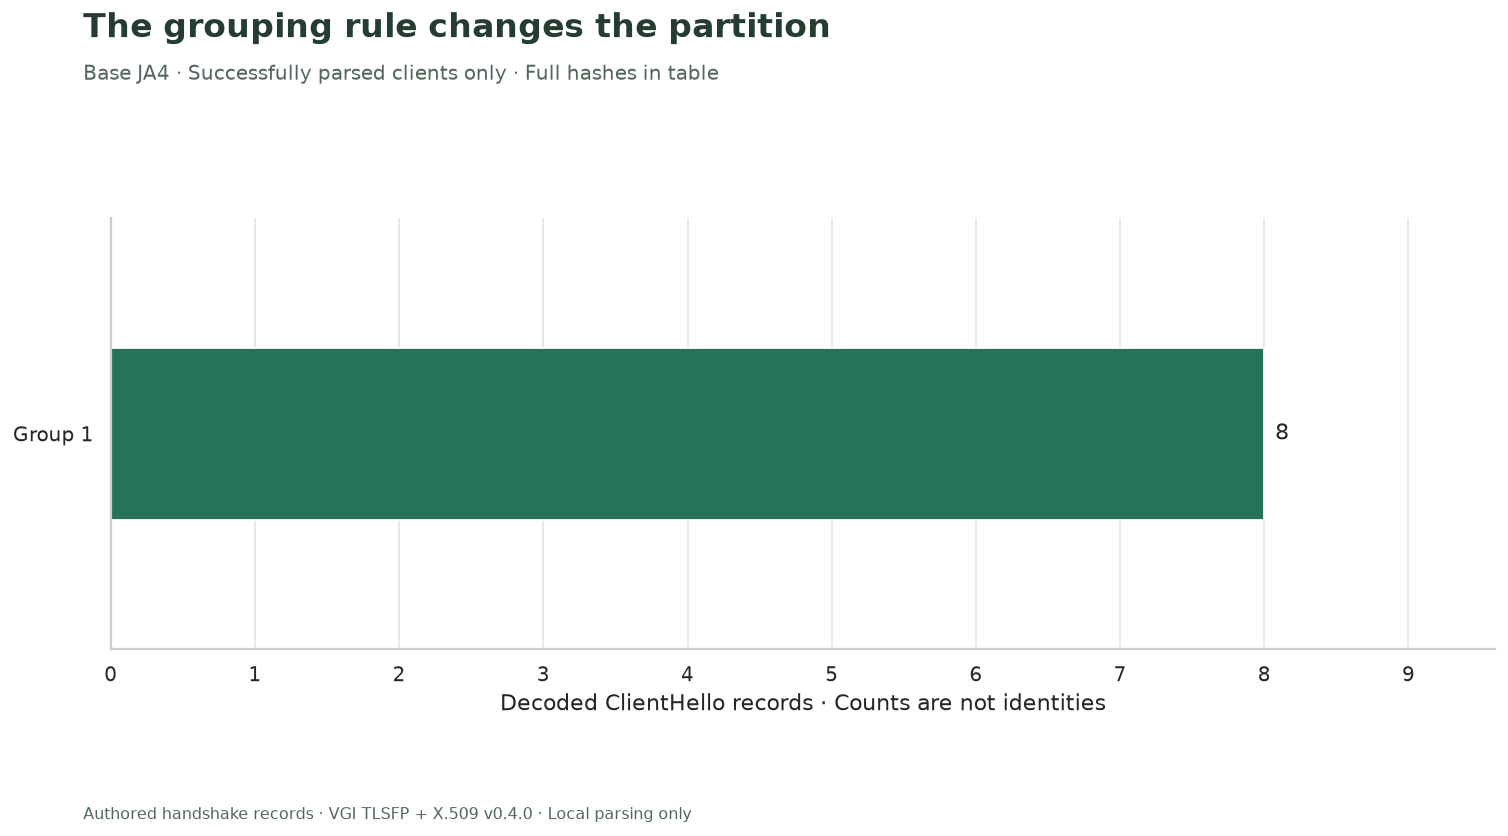

**8 decoded client records** form **1 Base JA4 groups**. Inspect the server-name and certificate counts below: one client fingerprint can occur with multiple supplied names and different certificate bytes. Those associations come from the authored capture IDs, not equality between fingerprint domains.

,group_label,selected_fingerprint,capture_records,byte_representations,supplied_server_names,certificate_fingerprints
0,Group 1,t13d1516h2_8daaf6152771_e5627efa2ab1,8,5,2,2


In [11]:
fig, ax = plt.subplots(figsize=(12, 6.5))
bars = ax.barh(groups.group_label, groups.capture_records, color="#267358", height=0.40)
ax.bar_label(bars, padding=6, fontsize=12)
ax.set_ylim(len(groups) - 0.5, -0.5)
ax.set_xlim(0, int(groups.capture_records.max()) * 1.2)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Decoded ClientHello records · Counts are not identities")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "The grouping rule changes the partition",
    f"{scheme} · Successfully parsed clients only · Full hashes in table",
    "02_fingerprint_groups.png",
    bottom=0.12,
)
prose(
    f"**{int(groups.capture_records.sum())} decoded client records** form **{len(groups)} {scheme} groups**. "
    "Inspect the server-name and certificate counts below: one client fingerprint can occur with multiple supplied names and different certificate bytes. "
    "Those associations come from the authored capture IDs, not equality between fingerprint domains."
)
display(groups)

## Check the variants, NULL behavior and correlation cardinality

These checks establish behavior of the pinned workers on the authored fixtures. They
do not assert that the byte records could complete a real TLS negotiation or uniquely
identify software. The comparison uses only the worker's supported JA3/JA3S and base
JA4 TLS-client surface.

In [12]:
%%sql checks <<
SELECT 'All twelve input records survive parsing' AS check_name,
 (SELECT count(*)=12 AND count(DISTINCT capture_id)=12 FROM decoded) AS passed
UNION ALL SELECT 'Eight client records are retained for grouping',
 (SELECT count(*)=8 FROM client_records)
UNION ALL SELECT 'Record framing preserves both client fingerprints',
 (SELECT count(DISTINCT ja3)=1 AND count(DISTINCT ja4)=1 FROM decoded WHERE pattern_id IN ('base','record'))
UNION ALL SELECT 'Cipher order changes JA3 but not base JA4',
 (SELECT count(DISTINCT ja3)=2 AND count(DISTINCT ja4)=1 FROM decoded WHERE pattern_id IN ('base','reversed-ciphers'))
UNION ALL SELECT 'GREASE variant stays in the same normalized groups',
 (SELECT count(DISTINCT ja3)=1 AND count(DISTINCT ja4)=1 FROM decoded WHERE pattern_id IN ('base','different-grease'))
UNION ALL SELECT 'Different supplied server names share both fingerprints',
 (SELECT count(DISTINCT parsed.sni)=2 AND count(DISTINCT ja3)=1 AND count(DISTINCT ja4)=1 FROM decoded WHERE pattern_id IN ('base','other-server'))
UNION ALL SELECT 'JA3 digest matches exposed pre-hash string',
 NOT EXISTS(SELECT 1 FROM decoded WHERE parsed IS NOT NULL AND ja3<>md5(ja3_string))
UNION ALL SELECT 'Header-only fixture proves guard is weaker than parse',
 (SELECT header_recognized AND parsed IS NULL AND ja3 IS NULL AND ja4 IS NULL FROM decoded WHERE pattern_id='header-only')
UNION ALL SELECT 'ServerHello retains its own role',
 (SELECT header_recognized AND parsed IS NULL AND ja3 IS NULL AND ja4 IS NULL AND ja3s IS NOT NULL FROM decoded WHERE pattern_id='server-hello')
UNION ALL SELECT 'Missing bytes propagate NULL outputs',
 (SELECT header_recognized IS NULL AND parsed IS NULL AND ja3 IS NULL AND ja4 IS NULL FROM decoded WHERE pattern_id='missing')
UNION ALL SELECT 'Capture correlation does not multiply rows and retains two certificates',
 (SELECT count(*)=8 AND count(DISTINCT capture_id)=8 AND count(DISTINCT certificate_sha256)=2 FROM client_records)
UNION ALL SELECT 'Selected grouping key exactly follows the chosen algorithm',
 NOT EXISTS(SELECT 1 FROM client_records WHERE selected_fingerprint IS DISTINCT FROM CASE WHEN {{ USE_JA4 }} THEN ja4 ELSE ja3 END);

In [13]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert (
    int(groups.capture_records.sum())
    == con.execute("SELECT count(*) FROM client_records").fetchone()[0]
)
assert (
    int(coverage.capture_records.sum())
    == con.execute("SELECT count(*) FROM captures").fetchone()[0]
)
prose(
    f"**{len(checks)} SQL checks and both population reconciliations passed.** Parsing coverage and fingerprint grouping remain separate."
)

**12 SQL checks and both population reconciliations passed.** Parsing coverage and fingerprint grouping remain separate.

## Experiment · preserve cipher order with JA3

Change only `USE_JA4` from **True to False**, restart, and run all. Predict which
variant splits from the main group. The population audit, decoded lists, server names,
certificate fingerprints and both precomputed TLS hashes should remain unchanged.

More groups do not mean more clients. This comparison shows the effect of one
normalization choice on these fixtures. Reset `USE_JA4=True` for the saved default.

In [14]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)